# Statistical Analysis

## Project Objective

This notebook applies statistical methods to investigate relationships and patterns in the E-Commerce & Customer Behaviour dataset.

### Analysis Plan
- Examine numerical distributions and assess statistical assumptions.
- Test relationships between selected numerical variables.
- Compare customer and order behaviour across groups.
- Analyse product ratings and review patterns.
- Interpret statistical significance alongside practical relevance.
- Document limitations and avoid unsupported causal conclusions.

**Important:** Statistical significance does not imply causation. Data quality issues and the dataset's characteristics will be considered when interpreting results.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Project paths
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

# Load source datasets
data = {
    name: pd.read_csv(RAW_DATA_DIR / f"{name}.csv")
    for name in [
        "products",
        "customers",
        "orders",
        "order_items",
        "reviews"
    ]
}

# Convert order timestamps to datetime
timestamp_columns = [
    "placed_at",
    "paid_at",
    "shipped_at",
    "delivered_at"
]

for column in timestamp_columns:
    data["orders"][column] = pd.to_datetime(
        data["orders"][column],
        errors="coerce",
        utc=True
    )

# Confirm successful loading
for name, df in data.items():
    print(f"{name}: {df.shape}")

print("\nAll datasets loaded successfully.")

products: (2000, 19)
customers: (800, 13)
orders: (3000, 21)
order_items: (6219, 10)
reviews: (2500, 10)

All datasets loaded successfully.


In [5]:
# Inspect the actual columns available in each dataset

for name, df in data.items():
    print(f"\n{name.upper()} — {len(df.columns)} columns")
    print(df.columns.tolist())

# Numerical descriptive statistics
for name, df in data.items():
    numeric_df = df.select_dtypes(include="number")

    # Exclude identifiers from numerical summaries
    id_columns = [
        col for col in numeric_df.columns
        if col.lower() == "id" or col.lower().endswith("_id")
    ]

    numeric_df = numeric_df.drop(columns=id_columns)

    print(f"\n{'=' * 50}")
    print(f"{name.upper()} — NUMERICAL PROFILE")
    print(f"{'=' * 50}")

    if numeric_df.empty:
        print("No numerical columns available.")
    else:
        display(numeric_df.describe().round(2).T)

# Check order status distribution
print("\nORDER STATUS COUNTS")

if "status" in data["orders"].columns:
    display(
        data["orders"]["status"]
        .value_counts(dropna=False)
        .to_frame("count")
    )
else:
    print("No status column found.")


PRODUCTS — 19 columns
['id', 'created_at', 'updated_at', 'sku', 'name', 'slug', 'description', 'category_id', 'brand', 'price', 'compare_at_price', 'currency', 'color', 'weight_g', 'tags', 'in_stock', 'rating', 'review_count', 'status']

CUSTOMERS — 13 columns
['id', 'created_at', 'updated_at', 'name', 'email', 'phone', 'company', 'address', 'tier', 'marketing_opt_in', 'orders_count', 'total_spent', 'notes']

ORDERS — 21 columns
['id', 'created_at', 'updated_at', 'number', 'customer_id', 'status', 'subtotal', 'shipping', 'tax', 'discount', 'total', 'currency', 'payment_method', 'shipping_address', 'shipping_method', 'tracking_number', 'placed_at', 'paid_at', 'shipped_at', 'delivered_at', 'notes']

ORDER_ITEMS — 10 columns
['id', 'created_at', 'updated_at', 'order_id', 'product_id', 'sku', 'name', 'quantity', 'unit_price', 'line_total']

REVIEWS — 10 columns
['id', 'created_at', 'updated_at', 'product_id', 'customer_id', 'rating', 'title', 'body', 'verified_purchase', 'helpful_votes']


,count,mean,std,min,25%,50%,75%,max
price,2000.0,468.16,636.59,5.14,86.64,240.72,559.28,3492.50
compare_at_price,355.0,636.43,927.54,8.65,108.60,286.98,722.44,5049.64
weight_g,2000.0,5979.05,3400.46,87.00,3012.50,5906.50,8836.25,11993.00
rating,1441.0,3.92,1.00,1.00,3.30,4.00,5.00,5.00
review_count,2000.0,1.25,1.10,0.00,0.00,1.00,2.00,6.00



CUSTOMERS — NUMERICAL PROFILE


,count,mean,std,min,25%,50%,75%,max
orders_count,800.0,3.40,1.95,0.0,2.00,3.00,5.00,12.00
total_spent,800.0,4855.65,4275.98,0.0,1513.62,3877.88,6892.04,30063.98



ORDERS — NUMERICAL PROFILE


...

,count,mean,std,min,25%,50%,75%,max
quantity,6219.0,1.43,0.75,1.00,1.00,1.00,2.00,4.0
unit_price,6219.0,451.94,623.05,5.14,82.64,220.56,536.27,3492.5
line_total,6219.0,649.53,1084.54,5.14,108.55,280.76,705.10,13970.0



REVIEWS — NUMERICAL PROFILE


,count,mean,std,min,25%,50%,75%,max
rating,2500.0,3.91,1.20,1.0,3.0,4.0,5.0,5.0
helpful_votes,2500.0,4.57,8.91,0.0,0.0,1.0,4.0,40.0



ORDER STATUS COUNTS


,count
status,
delivered,2675
cancelled,173
refunded,104
shipped,32
paid,9
pending,7


In [6]:
# Question:
# Is customer order count associated with total spending?

customers = data["customers"]

# Select the two variables and remove missing values
customer_metrics = customers[
    ["orders_count", "total_spent"]
].dropna()

# Pearson correlation: linear association
pearson_r, pearson_p = stats.pearsonr(
    customer_metrics["orders_count"],
    customer_metrics["total_spent"]
)

# Spearman correlation: monotonic association based on ranks
spearman_rho, spearman_p = stats.spearmanr(
    customer_metrics["orders_count"],
    customer_metrics["total_spent"]
)

print("Customer Order Count vs Total Spending")
print("-" * 45)
print(f"Observations: {len(customer_metrics)}")
print(f"Pearson correlation:  {pearson_r:.4f}")
print(f"Pearson p-value:      {pearson_p:.6g}")
print(f"Spearman correlation: {spearman_rho:.4f}")
print(f"Spearman p-value:     {spearman_p:.6g}")

alpha = 0.05

print("\nInterpretation:")
if pearson_p < alpha:
    print("Pearson correlation is statistically significant at alpha = 0.05.")
else:
    print("Pearson correlation is not statistically significant at alpha = 0.05.")

if spearman_p < alpha:
    print("Spearman correlation is statistically significant at alpha = 0.05.")
else:
    print("Spearman correlation is not statistically significant at alpha = 0.05.")

print(
    "\nCaution: Customer summary metrics were previously found to be "
    "inconsistent with aggregates recalculated from the orders table. "
    "Interpret these results as associations in the recorded customer "
    "metrics, not as fully validated purchasing behaviour."
)

Customer Order Count vs Total Spending
---------------------------------------------
Observations: 800
Pearson correlation:  0.6158
Pearson p-value:      1.10221e-84
Spearman correlation: 0.6901
Spearman p-value:     3.66352e-114

Interpretation:
Pearson correlation is statistically significant at alpha = 0.05.
Spearman correlation is statistically significant at alpha = 0.05.

Caution: Customer summary metrics were previously found to be inconsistent with aggregates recalculated from the orders table. Interpret these results as associations in the recorded customer metrics, not as fully validated purchasing behaviour.


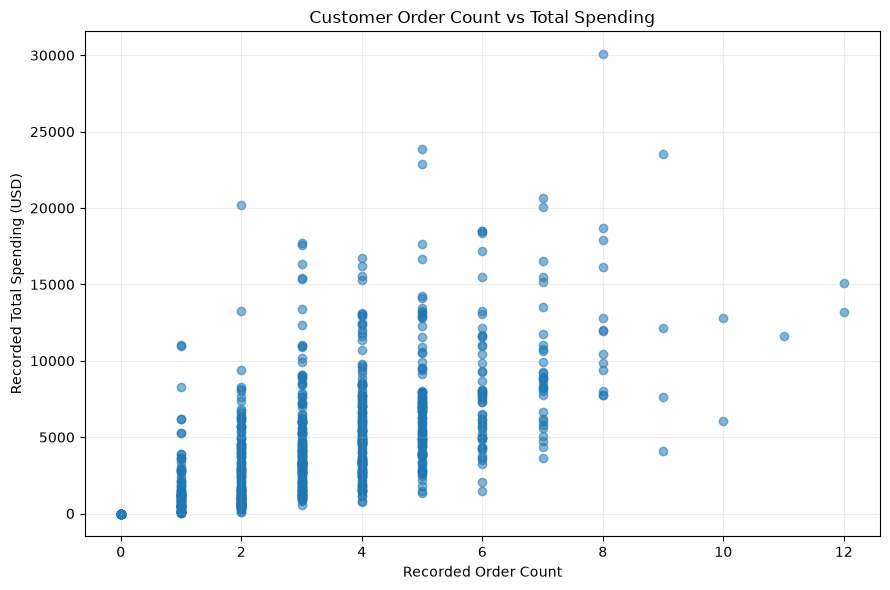

In [7]:
# Visualize order count vs total spending

customers = data["customers"]

plt.figure(figsize=(9, 6))

plt.scatter(
    customers["orders_count"],
    customers["total_spent"],
    alpha=0.55
)

plt.title("Customer Order Count vs Total Spending")
plt.xlabel("Recorded Order Count")
plt.ylabel("Recorded Total Spending (USD)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [8]:
# Statistical relationship: Product Price vs Review Rating

products = data["products"].copy()

# Keep products with both price and rating available
price_rating = products[["price", "rating"]].dropna()

# Pearson: linear relationship
pearson_r, pearson_p = stats.pearsonr(
    price_rating["price"],
    price_rating["rating"]
)

# Spearman: monotonic relationship
spearman_rho, spearman_p = stats.spearmanr(
    price_rating["price"],
    price_rating["rating"]
)

print("PRODUCT PRICE VS REVIEW RATING")
print("-" * 40)
print(f"Products analysed: {len(price_rating)}")
print(f"Pearson correlation:  {pearson_r:.4f}")
print(f"Pearson p-value:      {pearson_p:.6g}")
print(f"Spearman correlation: {spearman_rho:.4f}")
print(f"Spearman p-value:     {spearman_p:.6g}")

alpha = 0.05

print("\nINTERPRETATION")
if pearson_p < alpha:
    print("Pearson: statistically significant linear association.")
else:
    print("Pearson: no statistically significant linear association.")

if spearman_p < alpha:
    print("Spearman: statistically significant monotonic association.")
else:
    print("Spearman: no statistically significant monotonic association.")

print(
    "\nReminder: Correlation does not establish causation. "
    "Only products with available ratings were included."
)

PRODUCT PRICE VS REVIEW RATING
----------------------------------------
Products analysed: 1441
Pearson correlation:  0.0184
Pearson p-value:      0.484544
Spearman correlation: 0.0456
Spearman p-value:     0.0837114

INTERPRETATION
Pearson: no statistically significant linear association.
Spearman: no statistically significant monotonic association.

Reminder: Correlation does not establish causation. Only products with available ratings were included.


In [9]:
# Statistical relationship: Discount vs Order Total

orders = data["orders"].copy()

discount_total = orders[["discount", "total"]].dropna()

pearson_r, pearson_p = stats.pearsonr(
    discount_total["discount"],
    discount_total["total"]
)

spearman_rho, spearman_p = stats.spearmanr(
    discount_total["discount"],
    discount_total["total"]
)

print("DISCOUNT VS ORDER TOTAL")
print("-" * 40)
print(f"Orders analysed: {len(discount_total)}")
print(f"Pearson correlation:  {pearson_r:.4f}")
print(f"Pearson p-value:      {pearson_p:.6g}")
print(f"Spearman correlation: {spearman_rho:.4f}")
print(f"Spearman p-value:     {spearman_p:.6g}")

alpha = 0.05

print("\nINTERPRETATION")

if pearson_p < alpha:
    print("Pearson: statistically significant linear association.")
else:
    print("Pearson: no statistically significant linear association.")

if spearman_p < alpha:
    print("Spearman: statistically significant monotonic association.")
else:
    print("Spearman: no statistically significant monotonic association.")

print(
    "\nReminder: This is an association, not evidence that discounts "
    "cause higher or lower order totals. All order statuses are included."
)

DISCOUNT VS ORDER TOTAL
----------------------------------------
Orders analysed: 3000
Pearson correlation:  0.1988
Pearson p-value:      3.95706e-28
Spearman correlation: -0.0092
Spearman p-value:     0.614773

INTERPRETATION
Pearson: statistically significant linear association.
Spearman: no statistically significant monotonic association.

Reminder: This is an association, not evidence that discounts cause higher or lower order totals. All order statuses are included.


In [10]:
# Statistical test: Order Total Across Customer Tiers

orders = data["orders"].copy()
customers = data["customers"].copy()

tier_orders = orders.merge(
    customers[["id", "tier"]],
    left_on="customer_id",
    right_on="id",
    how="left",
    validate="many_to_one"
)

tier_orders = tier_orders[["tier", "total"]].dropna()

groups = {
    tier: group["total"].to_numpy()
    for tier, group in tier_orders.groupby("tier")
}

print("ORDER TOTAL ACROSS CUSTOMER TIERS")
print("-" * 45)

for tier, values in groups.items():
    print(
        f"{tier}: n={len(values)}, "
        f"median=${np.median(values):,.2f}, "
        f"mean=${np.mean(values):,.2f}"
    )

if len(groups) >= 2:
    h_stat, p_value = stats.kruskal(*groups.values())

    print(f"\nKruskal-Wallis H-statistic: {h_stat:.4f}")
    print(f"p-value: {p_value:.6g}")

    if p_value < 0.05:
        print(
            "Result: At least one tier differs statistically "
            "from another in its order-total distribution."
        )
    else:
        print(
            "Result: No statistically significant difference "
            "was detected between the tier distributions."
        )

print(
    "\nNote: All order statuses are included. "
    "A significant result does not identify which tiers differ; "
    "post-hoc testing would be needed."
)

ORDER TOTAL ACROSS CUSTOMER TIERS
---------------------------------------------
gold: n=468, median=$802.23, mean=$1,389.04
platinum: n=182, median=$798.46, mean=$1,338.22
silver: n=668, median=$774.25, mean=$1,516.68
standard: n=1682, median=$790.03, mean=$1,411.13

Kruskal-Wallis H-statistic: 0.4342
p-value: 0.933082
Result: No statistically significant difference was detected between the tier distributions.

Note: All order statuses are included. A significant result does not identify which tiers differ; post-hoc testing would be needed.


In [11]:
# Statistical test: Review Ratings Across Product Categories

products = data["products"].copy()
reviews = data["reviews"].copy()

category_reviews = reviews.merge(
    products[["id", "category_id"]],
    left_on="product_id",
    right_on="id",
    how="left",
    validate="many_to_one"
)

category_reviews = category_reviews[
    ["category_id", "rating"]
].dropna()

groups = {
    category: group["rating"].to_numpy()
    for category, group in category_reviews.groupby("category_id")
}

print("REVIEW RATINGS ACROSS PRODUCT CATEGORIES")
print("-" * 50)

for category, values in groups.items():
    print(
        f"Category {category}: n={len(values)}, "
        f"median rating={np.median(values):.2f}, "
        f"mean rating={np.mean(values):.2f}"
    )

if len(groups) >= 2:
    h_stat, p_value = stats.kruskal(*groups.values())

    print(f"\nKruskal-Wallis H-statistic: {h_stat:.4f}")
    print(f"p-value: {p_value:.6g}")

    if p_value < 0.05:
        print(
            "Result: At least one category has a statistically "
            "different rating distribution."
        )
    else:
        print(
            "Result: No statistically significant difference "
            "in rating distributions was detected across categories."
        )

print(
    "\nNote: Ratings are ordinal. A significant result would not "
    "tell us which categories differ without post-hoc tests."
)

REVIEW RATINGS ACROSS PRODUCT CATEGORIES
--------------------------------------------------
Category 1: n=310, median rating=4.00, mean rating=3.90
Category 2: n=321, median rating=4.00, mean rating=3.98
Category 3: n=357, median rating=4.00, mean rating=3.97
Category 4: n=309, median rating=4.00, mean rating=3.90
Category 5: n=322, median rating=4.00, mean rating=3.89
Category 6: n=296, median rating=4.00, mean rating=3.86
Category 7: n=291, median rating=4.00, mean rating=3.93
Category 8: n=294, median rating=4.00, mean rating=3.87

Kruskal-Wallis H-statistic: 3.3121
p-value: 0.854706
Result: No statistically significant difference in rating distributions was detected across categories.

Note: Ratings are ordinal. A significant result would not tell us which categories differ without post-hoc tests.


In [12]:
# Statistical test: Helpful Votes Across Rating Groups

reviews = data["reviews"].copy()

reviews["rating_group"] = pd.cut(
    reviews["rating"],
    bins=[0, 2, 3, 5],
    labels=["Low (1-2)", "Medium (3)", "High (4-5)"]
)

rating_groups = {
    group: subset["helpful_votes"].dropna().to_numpy()
    for group, subset in reviews.groupby(
        "rating_group", observed=True
    )
}

print("HELPFUL VOTES ACROSS RATING GROUPS")
print("-" * 45)

for group, values in rating_groups.items():
    print(
        f"{group}: n={len(values)}, "
        f"median={np.median(values):.2f}, "
        f"mean={np.mean(values):.2f}"
    )

h_stat, p_value = stats.kruskal(*rating_groups.values())

print(f"\nKruskal-Wallis H-statistic: {h_stat:.4f}")
print(f"p-value: {p_value:.6g}")

if p_value < 0.05:
    print(
        "Result: At least one rating group differs statistically "
        "in its helpful-vote distribution."
    )
else:
    print(
        "Result: No statistically significant difference was "
        "detected in helpful-vote distributions."
    )

print(
    "\nNote: This test identifies overall group differences, "
    "not which specific pairs differ. Association does not imply causation."
)

HELPFUL VOTES ACROSS RATING GROUPS
---------------------------------------------
Low (1-2): n=355, median=1.00, mean=4.83
Medium (3): n=379, median=1.00, mean=4.70
High (4-5): n=1766, median=0.00, mean=4.50

Kruskal-Wallis H-statistic: 3.0760
p-value: 0.214811
Result: No statistically significant difference was detected in helpful-vote distributions.

Note: This test identifies overall group differences, not which specific pairs differ. Association does not imply causation.


In [13]:
# Summary of statistical hypothesis tests

statistical_summary = pd.DataFrame([
    {
        "Analysis": "Customer order count vs total spending",
        "Test": "Pearson correlation",
        "Statistic": 0.6158,
        "P_value": 1.10221e-84,
        "Significant_at_0.05": True
    },
    {
        "Analysis": "Product price vs review rating",
        "Test": "Pearson correlation",
        "Statistic": 0.0184,
        "P_value": 0.484544,
        "Significant_at_0.05": False
    },
    {
        "Analysis": "Product price vs review rating",
        "Test": "Spearman correlation",
        "Statistic": 0.0456,
        "P_value": 0.0837114,
        "Significant_at_0.05": False
    },
    {
        "Analysis": "Discount vs order total",
        "Test": "Pearson correlation",
        "Statistic": 0.1988,
        "P_value": 3.95706e-28,
        "Significant_at_0.05": True
    },
    {
        "Analysis": "Discount vs order total",
        "Test": "Spearman correlation",
        "Statistic": -0.0092,
        "P_value": 0.614773,
        "Significant_at_0.05": False
    },
    {
        "Analysis": "Order total across customer tiers",
        "Test": "Kruskal-Wallis",
        "Statistic": 0.4342,
        "P_value": 0.933082,
        "Significant_at_0.05": False
    },
    {
        "Analysis": "Review ratings across product categories",
        "Test": "Kruskal-Wallis",
        "Statistic": 3.3121,
        "P_value": 0.854706,
        "Significant_at_0.05": False
    },
    {
        "Analysis": "Helpful votes across rating groups",
        "Test": "Kruskal-Wallis",
        "Statistic": 3.0760,
        "P_value": 0.214811,
        "Significant_at_0.05": False
    }
])

display(
    statistical_summary.style.format({
        "Statistic": "{:.4f}",
        "P_value": "{:.3e}"
    })
)

print("\nTotal tests recorded:", len(statistical_summary))
print(
    "Significant tests at alpha = 0.05:",
    statistical_summary["Significant_at_0.05"].sum()
)

,Analysis,Test,Statistic,P_value,Significant_at_0.05
0,Customer order count vs total spending,Pearson correlation,0.6158,1.102e-84,True
1,Product price vs review rating,Pearson correlation,0.0184,4.845e-01,False
2,Product price vs review rating,Spearman correlation,0.0456,8.371e-02,False
3,Discount vs order total,Pearson correlation,0.1988,3.957e-28,True
4,Discount vs order total,Spearman correlation,-0.0092,6.148e-01,False
5,Order total across customer tiers,Kruskal-Wallis,0.4342,9.331e-01,False
6,Review ratings across product categories,Kruskal-Wallis,3.3121,8.547e-01,False
7,Helpful votes across rating groups,Kruskal-Wallis,3.0760,2.148e-01,False



Total tests recorded: 8
Significant tests at alpha = 0.05: 2


In [15]:
# Multiple-testing correction: Benjamini-Hochberg (BH)

raw_p_values = statistical_summary["P_value"].to_numpy(dtype=float)

m = len(raw_p_values)

# Sort p-values from smallest to largest
sorted_indices = np.argsort(raw_p_values)
sorted_p_values = raw_p_values[sorted_indices]

# Calculate BH-adjusted p-values
sorted_adjusted = sorted_p_values * m / np.arange(1, m + 1)

# Enforce monotonicity and cap adjusted p-values at 1
sorted_adjusted = np.minimum.accumulate(sorted_adjusted[::-1])[::-1]
sorted_adjusted = np.clip(sorted_adjusted, 0, 1)

# Restore original row order
adjusted_p_values = np.empty(m)
adjusted_p_values[sorted_indices] = sorted_adjusted

statistical_summary["Adjusted_P_value"] = adjusted_p_values
statistical_summary["Significant_after_correction"] = (
    adjusted_p_values < 0.05
)

display(
    statistical_summary.style.format({
        "Statistic": "{:.4f}",
        "P_value": "{:.3e}",
        "Adjusted_P_value": "{:.3e}"
    })
)

print(
    "\nSignificant tests after BH correction:",
    int(statistical_summary["Significant_after_correction"].sum()),
    "out of",
    m
)

,Analysis,Test,Statistic,P_value,Significant_at_0.05,Adjusted_P_value,Significant_after_correction
0,Customer order count vs total spending,Pearson correlation,0.6158,1.102e-84,True,8.818e-84,True
1,Product price vs review rating,Pearson correlation,0.0184,4.845e-01,False,7.753e-01,False
2,Product price vs review rating,Spearman correlation,0.0456,8.371e-02,False,2.232e-01,False
3,Discount vs order total,Pearson correlation,0.1988,3.957e-28,True,1.583e-27,True
4,Discount vs order total,Spearman correlation,-0.0092,6.148e-01,False,8.197e-01,False
5,Order total across customer tiers,Kruskal-Wallis,0.4342,9.331e-01,False,9.331e-01,False
6,Review ratings across product categories,Kruskal-Wallis,3.3121,8.547e-01,False,9.331e-01,False
7,Helpful votes across rating groups,Kruskal-Wallis,3.0760,2.148e-01,False,4.296e-01,False



Significant tests after BH correction: 2 out of 8


## Statistical Analysis — Key Findings

### 1. Customer Order Count and Total Spending
A moderate positive correlation was found between recorded customer order counts and total spending (Pearson's \(r = 0.6158\), \(p < 0.001\)). The relationship remained statistically significant after Benjamini–Hochberg correction. However, customer summary metrics were previously found to be inconsistent with aggregates recalculated from the orders table. Therefore, this result should be interpreted cautiously.

### 2. Product Price and Review Rating
No statistically significant linear or monotonic association was detected between product price and rating among the 1,441 products with available ratings (Pearson's \(r = 0.0184\), \(p = 0.485\); Spearman's \(\rho = 0.0456\), \(p = 0.084\)).

### 3. Discount and Order Total
Pearson's correlation indicated a weak positive linear association between discount and order total (\(r = 0.1988\), \(p < 0.001\)). However, Spearman's correlation was not statistically significant (\(\rho = -0.0092\), \(p = 0.615\)). This difference suggests that the relationship may not represent a consistent monotonic pattern. Further investigation of the data distribution and potential outliers is warranted. These findings do not establish a causal effect of discounts on order totals.

### 4. Order Total Across Customer Tiers
The Kruskal–Wallis test detected no statistically significant difference in order-total distributions across customer tiers (\(H = 0.4342\), \(p = 0.933\)).

### 5. Review Ratings Across Product Categories
No statistically significant difference in rating distributions was detected across the eight product categories (\(H = 3.3121\), \(p = 0.855\)). The median rating was 4 across all categories.

### 6. Helpful Votes Across Rating Groups
No statistically significant difference in helpful-vote distributions was detected between low-, medium-, and high-rating groups (\(H = 3.0760\), \(p = 0.215\)).

### Multiple-Testing Correction
The Benjamini–Hochberg procedure was applied to the eight recorded p-values. Two tests remained statistically significant after correction: the correlation between customer order count and total spending, and the Pearson correlation between discount and order total. Pearson and Spearman tests examine the same variable pairs, so the results are not fully independent.

### Limitations
- Statistical significance does not necessarily imply practical importance.
- Correlation does not establish causation.
- Customer summary metrics do not consistently match order-level aggregates.
- All order statuses were included in order-total comparisons; order totals should not automatically be interpreted as realized revenue.
- Missing product ratings were excluded from the price-rating analysis.
- No post-hoc pairwise comparisons were performed because the Kruskal–Wallis tests were not statistically significant.
- These findings describe this dataset and may not generalize to other e-commerce businesses.